# 07 — Modèle de reconstitution entraîné sur données marocaines

**Détection d'anomalies fiscales par des techniques de l'Intelligence Artificielle :**
**cas de la Direction Régionale des Impôts de Tétouan**

---

Les notebooks 01 à 05 construisent et valident un modèle sur **JAR2020** — 146 045 états financiers d'entreprises américaines cotées. Le notebook 06 montre que ce modèle, transposé tel quel à un portefeuille marocain, **classe par taille d'entreprise et non par anomalie** (`docs/06_transferabilite.md`).

Ce notebook répond à la question qui en découle : **peut-on entraîner un modèle d'apprentissage directement sur des données marocaines, sans disposer d'aucune étiquette de fraude ?**

La réponse tient en une idée. Un modèle supervisé de détection de fraude a besoin d'étiquettes — « cette entreprise a fraudé, celle-là non ». Au Maroc, ces étiquettes n'existent pas et ne peuvent pas exister hors de l'administration (secret professionnel, art. 246 du CGI). **Mais il existe une cible qui, elle, est disponible sur chaque liasse : le montant déclaré lui-même.**

On n'apprend donc pas à prédire la fraude. On apprend à prédire **ce qu'un contribuable aurait normalement déclaré**, compte tenu du reste de sa liasse — appareil productif, stocks, achats, créances, secteur — puis on mesure l'écart avec ce qu'il a effectivement déclaré. C'est la transposition, en apprentissage automatique, de la **reconstitution du chiffre d'affaires** que pratique un vérificateur lorsqu'il écarte une comptabilité (art. 213 du CGI).

Implémentation : [`src/modele_marocain.py`](../src/modele_marocain.py) (le modèle) et [`src/ciblage.py`](../src/ciblage.py) (orchestration avec la règle de rupture des notebooks 06). Documentation complète : [`docs/07_modele_reconstitution.md`](../docs/07_modele_reconstitution.md).

> ## ⚠️ Statut de ce notebook — à lire avant d'interpréter quoi que ce soit
>
> Le portefeuille utilisé est le **portefeuille simulé de la DRI de Tétouan** (220 contribuables fictifs × 4 exercices), généré par `scripts/generer_jeu_test_marocain.py`. Aucune entreprise réelle, aucun identifiant fiscal réel.
>
> Les anomalies de ce portefeuille sont **plantées par nous** pour permettre l'évaluation. Cela valide que la chaîne de traitement fonctionne et que le modèle apprend un signal réel — **cela ne mesure pas** sa capacité à détecter de la fraude fiscale marocaine réelle : cela supposerait des dossiers authentiques et une vérité terrain issue de vérifications définitives, précisément ce que l'article 246 du CGI rend inaccessible.

In [1]:
import sys
from pathlib import Path

# Rend `src/` importable, que le notebook soit lancé depuis notebooks/ ou depuis la racine.
RACINE = Path.cwd()
if not (RACINE / "src").is_dir():
    RACINE = RACINE.parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

from src.liasse_mapping import mapper_liasse
from src.modele_marocain import (
    CIBLES, entrainer_reconstitution, expliquer_reconstitution, scorer_reconstitution,
)
from src.regle_rupture import scorer_global
from src.ciblage import analyser_portefeuille

# Palette catégorielle validée — la même que les notebooks 01 à 06 et le volet
# technique du dashboard (validate_palette.js : tous les contrôles passent).
BLUE, ORANGE, GRAY, INK, INK_SOFT, SURFACE = (
    "#2a78d6", "#eb6834", "#888780", "#0b0b0b", "#52514e", "#fcfcfb",
)


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.figure.patch.set_facecolor(SURFACE)
    for cote in ("top", "right"):
        ax.spines[cote].set_visible(False)
    for cote in ("left", "bottom"):
        ax.spines[cote].set_color("#d7d7d3")
    ax.tick_params(colors=INK_SOFT, labelsize=9)
    ax.grid(True, color="#e8e8e4", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.xaxis.label.set_color(INK_SOFT)
    ax.yaxis.label.set_color(INK_SOFT)
    ax.title.set_color(INK)
    return ax


pd.set_option("display.max_columns", 20)
print("Environnement prêt.")

Environnement prêt.


---
## 1. Trois grandeurs reconstituées

Le choix des variables explicatives est le point délicat. Deux écueils symétriques : trop peu de variables et le modèle prédit mal (tout le monde paraît anormal) ; une variable trop proche de la cible et le modèle la recopie (plus personne ne paraît anormal). Prédire la charge d'impôt à partir du résultat courant donnerait un modèle excellent et inutile — l'impôt est mécaniquement proportionnel au résultat. Chaque cible est donc prédite à partir de **l'appareil productif**, jamais d'une autre grandeur déclarative.

| Cible | Prédite à partir de… | Volontairement exclu | Écart négatif suggère |
|---|---|---|---|
| Chiffre d'affaires | Immobilisations, stocks, achats, créances, dette | Résultat, impôt | Ventes non déclarées |
| Charge d'impôt | Appareil productif **et** chiffre d'affaires | Résultat net, résultat courant | Charges non justifiées, provisions non déductibles |
| Résultat net | Appareil productif, chiffre d'affaires, dette | Résultat courant, impôt | Minoration de la base imposable |

Seuls les écarts **négatifs** comptent dans le score final : déclarer plus que la norme n'est pas un risque fiscal.

In [2]:
pd.DataFrame([
    {"Cible": c.libelle, "Variables explicatives": len(c.variables),
     "Exclusions volontaires": ", ".join(c.exclusions), "Poids": c.poids}
    for c in CIBLES
])

,Cible,Variables explicatives,Exclusions volontaires,Poids
0,Chiffre d'affaires,14,"ni, ib, txt, re",1.2
1,Charge d'impôt sur les résultats,14,"ni, ib, txp",1.0
2,Résultat net,15,"ib, txt, re",1.0


---
## 2. Chargement du portefeuille simulé

In [3]:
CHEMIN_PORTEFEUILLE = RACINE / "data" / "exemples_marocains" / "portefeuille_dri_tetouan.csv"
CHEMIN_CLE = RACINE / "data" / "exemples_marocains" / "cle_anomalies.csv"

if not CHEMIN_PORTEFEUILLE.exists():
    raise FileNotFoundError("Générez le portefeuille : python scripts/generer_jeu_test_marocain.py")

brut = pd.read_csv(CHEMIN_PORTEFEUILLE)
cle = pd.read_csv(CHEMIN_CLE)
donnees, rapport = mapper_liasse(brut, unite="dirhams")

print(f"{len(donnees)} lignes — {donnees['gvkey'].nunique()} contribuables × "
      f"{donnees['fyear'].nunique()} exercices — {int(cle['anomalie'].sum())} lignes avec anomalie plantée")
donnees[["gvkey", "fyear", "secteur", "sale", "txt", "ni"]].head()

880 lignes — 220 contribuables × 4 exercices — 34 lignes avec anomalie plantée


,gvkey,fyear,secteur,sale,txt,ni
0,15000055,2021,Transport et logistique,0.087175,0.001077,0.003390
1,15000055,2022,Transport et logistique,0.087311,0.001035,0.003201
2,15000055,2023,Transport et logistique,0.091192,0.001051,0.003298
3,15000055,2024,Transport et logistique,0.091274,0.001075,0.003394
4,15000186,2021,Sante et cliniques,4.714040,0.158803,0.626844


---
## 3. Le piège du biais d'échelle

Le log signé naïf, `sign(x)·log(1+|x|)`, **n'est pas invariant d'échelle** : autour de 1 il se comporte comme l'identité, autour de 10⁶ comme un logarithme. Selon que les montants sont saisis en dirhams ou en millions, la compression n'est donc pas la même — et un modèle entraîné dessus réapprend la taille de l'entreprise au lieu de la neutraliser.

C'est très exactement le défaut qui disqualifie le modèle JAR2020 sur données marocaines (notebook 06) : 48 de ses 54 variables sont des variables de niveau. Un premier essai du modèle de reconstitution a reproduit ce défaut avant d'être corrigé — la cellule suivante l'illustre mathématiquement, sur trois échelles arbitraires.

In [4]:
valeurs_test = np.array([500.0, 50_000.0, 5_000_000.0])  # même « forme » de distribution, 3 échelles


def log_signe_naif(x):
    return np.sign(x) * np.log1p(np.abs(x))


def log_signe_normalise(x):
    # équivalent de src.modele_marocain._log_signe : normalise par l'échelle
    # médiane de la colonne avant le log, pour que log1p se comporte comme un
    # vrai logarithme quelle que soit l'unité de saisie.
    echelle = np.median(np.abs(x)) * 1e-3
    return np.sign(x) * np.log1p(np.abs(x) / echelle)


comparaison = pd.DataFrame({
    "Valeur (dirhams)": valeurs_test,
    "Log signé naïf": log_signe_naif(valeurs_test),
    "Log signé normalisé": log_signe_normalise(valeurs_test),
})
# Le même portefeuille, mais saisi en MILLIERS de dirhams : les valeurs sous-jacentes
# sont identiques, seule l'unité change.
comparaison["Log signé naïf (milliers)"] = log_signe_naif(valeurs_test / 1000)
comparaison["Log signé normalisé (milliers)"] = log_signe_normalise(valeurs_test / 1000)
comparaison

,Valeur (dirhams),Log signé naïf,Log signé normalisé,Log signé naïf (milliers),Log signé normalisé (milliers)
0,500.0,6.216606,2.397895,0.405465,2.397895
1,50000.0,10.819798,6.908755,3.931826,6.908755
2,5000000.0,15.424949,11.512935,8.517393,11.512935


Le log signé naïf change de valeur selon l'unité choisie (colonnes 2 vs 4) — un modèle entraîné dessus n'est donc pas invariant d'échelle. Le log signé normalisé, lui, donne des valeurs identiques quelle que soit l'unité (colonnes 3 vs 5) : c'est la version utilisée par `src.modele_marocain._log_signe`.

**Preuve empirique**, maintenant sur le vrai portefeuille et le vrai entraînement : le score de reconstitution doit être identique (à l'ordre de grandeur du hasard d'entraînement de XGBoost près) que le fichier soit saisi en dirhams ou en millions de dirhams.

In [5]:
donnees_millions, _ = mapper_liasse(brut, unite="millions_dirhams")

score_dirhams = scorer_reconstitution(donnees).set_index(["gvkey", "fyear"])["score_reconstitution"].sort_index()
score_millions = scorer_reconstitution(donnees_millions).set_index(["gvkey", "fyear"])["score_reconstitution"].sort_index()

correlation_rang = score_dirhams.rank().corr(score_millions.rank())
print(f"Corrélation de rang dirhams / millions de dirhams : {correlation_rang:.3f}")
print("(proche de 1 = le classement ne dépend pas de l'unité de saisie — "
      "exactement ce qui manquait au modèle JAR2020)")

Corrélation de rang dirhams / millions de dirhams : 1.000
(proche de 1 = le classement ne dépend pas de l'unité de saisie — exactement ce qui manquait au modèle JAR2020)


---
## 4. Entraînement — un contribuable jamais vu à l'entraînement ne prédit jamais lui-même

Si le modèle prédisait le chiffre d'affaires d'une entreprise qu'il a vue à l'entraînement, il reproduirait sa déclaration — y compris minorée — et l'écart s'annulerait. Toutes les prédictions ci-dessous sont donc produites par **validation croisée à 5 plis groupés par contribuable** (`GroupKFold` sur `gvkey`) : chaque dossier est prédit par un modèle qui ne l'a jamais vu, et jamais un exercice d'un contribuable n'entraîne le modèle qui prédit un autre exercice du même contribuable.

In [6]:
resultats = {c.nom: entrainer_reconstitution(donnees, c) for c in CIBLES}

r2_table = pd.DataFrame([
    {"Cible": c.libelle, "R² hors échantillon": resultats[c.nom]["r2"],
     "Lignes prédites": resultats[c.nom]["n_lignes_predites"]}
    for c in CIBLES
])
r2_table

,Cible,R² hors échantillon,Lignes prédites
0,Chiffre d'affaires,0.994337,880
1,Charge d'impôt sur les résultats,0.926743,880
2,Résultat net,0.933794,880


Ces R² élevés portent sur la prédiction du **niveau déclaratif normal**, pas sur la détection d'anomalie elle-même — un contribuable parfaitement sincère doit être prédit avec précision, sinon le moindre écart deviendrait un faux signal.

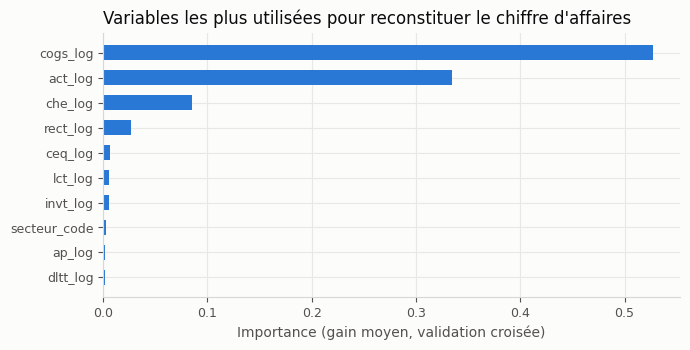

Figure enregistrée : reports/figures/07_modele_marocain_importances.png


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
style_axes(ax)
importances = resultats["sale"]["importances"].head(10).iloc[::-1]
ax.barh(importances.index, importances.values, color=BLUE, height=0.62)
ax.set_xlabel("Importance (gain moyen, validation croisée)")
ax.set_title("Variables les plus utilisées pour reconstituer le chiffre d'affaires",
             loc="left", color=INK)
fig.tight_layout()
CHEMIN_FIG_IMPORTANCES = RACINE / "reports" / "figures" / "07_modele_marocain_importances.png"
fig.savefig(CHEMIN_FIG_IMPORTANCES, dpi=150, facecolor=SURFACE)
plt.show()
print(f"Figure enregistrée : {CHEMIN_FIG_IMPORTANCES.relative_to(RACINE)}")

---
## 5. Score du portefeuille et explication d'un dossier

Seuls les écarts négatifs (sous-déclaration) alimentent le score — voir §1. Le dossier le plus signalé sert d'exemple pour la restitution destinée au vérificateur : montant déclaré, montant attendu, écart, et ce que cet écart suggère d'examiner.

In [8]:
score = scorer_reconstitution(donnees).reset_index(drop=True)

print(f"{int((score['score_reconstitution'] > 0).sum())} / {len(score)} dossiers "
      "avec au moins un signe de sous-déclaration")

score.sort_values("score_reconstitution", ascending=False).head(5)[[
    "gvkey", "fyear", "raison_sociale", "secteur",
    "score_reconstitution", "n_cibles_sous_declarees",
]]

644 / 880 dossiers avec au moins un signe de sous-déclaration


,gvkey,fyear,raison_sociale,secteur,score_reconstitution,n_cibles_sous_declarees
0,15022500,2022,MEDITERRANEE PROMOTION SNC,Promotion immobiliere,1.619993,3
1,15022500,2023,MEDITERRANEE PROMOTION SNC,Promotion immobiliere,1.301608,3
2,15022500,2024,MEDITERRANEE PROMOTION SNC,Promotion immobiliere,1.267202,3
3,15015072,2024,SALAM CERAMIQUE SARL AU,Negoce de materiaux,1.226384,3
4,15029494,2023,GROS FNIDEQ SA,Commerce de gros,1.030756,3


In [9]:
pire = score["score_reconstitution"].idxmax()
print(f"Dossier le plus signalé : {score.loc[pire, 'raison_sociale']} "
      f"— exercice {int(score.loc[pire, 'fyear'])}\n")

expliquer_reconstitution(score, pire)

Dossier le plus signalé : MEDITERRANEE PROMOTION SNC — exercice 2022



,grandeur,declare,attendu,ecart_pct,lecture
0,Charge d'impôt sur les résultats,0.003063,0.030471,-89.867031,La charge d'impôt est très inférieure à celle ...
1,Résultat net,0.010530,0.097121,-89.066877,Le résultat déclaré est très inférieur à celui...
2,Chiffre d'affaires,0.312291,0.552071,-43.316678,Le chiffre d'affaires déclaré est très inférie...


---
## 6. Complémentarité avec la règle de rupture — comparaison honnête par type d'anomalie

La comparaison globale favorise structurellement la règle de rupture (notebook 06 / `docs/06_transferabilite.md`) : les anomalies du portefeuille simulé ont été plantées comme des **distorsions de ratios**, ce que la règle détecte par construction. Isoler les anomalies selon qu'elles réduisent ou non la base imposable **déclarée** donne une lecture plus honnête de ce que chaque méthode apporte.

In [10]:
MINORATIONS = {"minoration_ca", "majoration_charges", "is_anormalement_bas"}
AUTRES = {"creances_fictives", "stocks_surevalues", "accruals_eleves", "rupture_trajectoire"}

cle_groupe = cle.copy()
cle_groupe["groupe"] = cle_groupe["profil_anomalie"].map(
    lambda p: "minoration" if p in MINORATIONS else ("autre" if p in AUTRES else "sain")
)

regles = scorer_global(donnees)
classement_combine, rapport_ciblage = analyser_portefeuille(donnees, methode="combine")


def evalue(scores_df, colonne_score, label):
    ev = scores_df.merge(
        cle_groupe[["identifiant_fiscal", "exercice", "anomalie", "groupe"]],
        left_on=["gvkey", "fyear"], right_on=["identifiant_fiscal", "exercice"],
        validate="one_to_one",
    )
    ligne = {
        "Méthode": label,
        "AUC-ROC globale": roc_auc_score(ev["anomalie"], ev[colonne_score]),
        "AUC-PR globale": average_precision_score(ev["anomalie"], ev[colonne_score]),
    }
    for groupe in ("minoration", "autre"):
        sous = ev[(ev["groupe"] == groupe) | (ev["groupe"] == "sain")]
        y = (sous["groupe"] == groupe).astype(int)
        ligne[f"AUC-ROC — {groupe}"] = roc_auc_score(y, sous[colonne_score])
    n_top5 = int(np.ceil(len(ev) * 0.05))
    ligne["Rappel top 5 %"] = ev.nlargest(n_top5, colonne_score)["anomalie"].sum() / ev["anomalie"].sum()
    return ligne


comparaison_methodes = pd.DataFrame([
    evalue(regles, "score_global", "Règles seules"),
    evalue(score, "score_reconstitution", "IA seule (reconstitution)"),
    evalue(classement_combine, "score_ciblage", "Combiné (règles + IA)"),
]).set_index("Méthode")

CHEMIN_COMPARAISON = RACINE / "reports" / "comparaison_regles_ia_marocain.csv"
comparaison_methodes.to_csv(CHEMIN_COMPARAISON)
print(f"Tableau enregistré : {CHEMIN_COMPARAISON.relative_to(RACINE)}")
comparaison_methodes.round(3)

Tableau enregistré : reports/comparaison_regles_ia_marocain.csv


,AUC-ROC globale,AUC-PR globale,AUC-ROC — minoration,AUC-ROC — autre,Rappel top 5 %
Méthode,,,,,
Règles seules,0.982,0.801,0.993,0.965,0.794
IA seule (reconstitution),0.828,0.405,0.946,0.639,0.382
Combiné (règles + IA),0.957,0.749,0.997,0.894,0.735


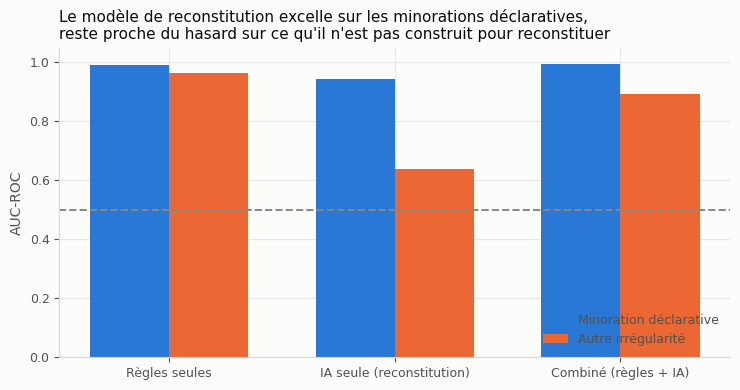

Figure enregistrée : reports/figures/07_modele_marocain_comparaison.png


In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))
style_axes(ax)

sous_ensemble = comparaison_methodes[["AUC-ROC — minoration", "AUC-ROC — autre"]]
largeur = 0.35
positions = np.arange(len(sous_ensemble))

ax.bar(positions - largeur / 2, sous_ensemble["AUC-ROC — minoration"], largeur,
       color=BLUE, label="Minoration déclarative")
ax.bar(positions + largeur / 2, sous_ensemble["AUC-ROC — autre"], largeur,
       color=ORANGE, label="Autre irrégularité")
ax.axhline(0.5, color=GRAY, linewidth=1.4, linestyle="--")
ax.annotate("hasard (0,5)", xy=(len(sous_ensemble) - 0.5, 0.5), xytext=(4, 4),
            textcoords="offset points", color=INK_SOFT, fontsize=9)

ax.set_xticks(positions)
ax.set_xticklabels(sous_ensemble.index)
ax.set_ylabel("AUC-ROC")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, labelcolor=INK_SOFT, fontsize=9, loc="lower right")
ax.set_title("Le modèle de reconstitution excelle sur les minorations déclaratives,\n"
             "reste proche du hasard sur ce qu'il n'est pas construit pour reconstituer",
             loc="left", color=INK, fontsize=11)
fig.tight_layout()

CHEMIN_FIG_COMPARAISON = RACINE / "reports" / "figures" / "07_modele_marocain_comparaison.png"
fig.savefig(CHEMIN_FIG_COMPARAISON, dpi=150, facecolor=SURFACE)
plt.show()
print(f"Figure enregistrée : {CHEMIN_FIG_COMPARAISON.relative_to(RACINE)}")

Le modèle de reconstitution reste, **à dessein**, peu sensible à ce qui n'affecte pas directement la base imposable déclarée (stocks surévalués, créances gonflées) : ce n'est pas ce qu'il a été construit pour reconstituer. Sur les minorations déclaratives en revanche, il approche la règle — et il apporte quelque chose qu'aucune règle ne donne : **un montant chiffré**, directement exploitable dans une procédure de reconstitution (art. 213 du CGI).

C'est pourquoi le dashboard combine les deux lectures par défaut (`src/ciblage.py`, `methode="combine"`, `poids_regles=0,6`) plutôt que de choisir l'une contre l'autre.

---
## 7. Conclusion

### Ce que ce notebook établit

1. **Un modèle appris sur données marocaines, sans étiquette de fraude, est possible.** Trois cibles (chiffre d'affaires, charge d'impôt, résultat net) sont reconstituées à partir du reste de la liasse, avec des R² hors échantillon supérieurs à 0,9.
2. **Le biais de taille qui disqualifie JAR2020 a été identifié et corrigé ici même** — le score de reconstitution est invariant à l'unité de saisie (dirhams / millions de dirhams), démontré empiriquement en §3.
3. **Le modèle est complémentaire de la règle de rupture, pas redondant.** Il excelle sur les minorations déclaratives (AUC-ROC proche de la règle) et apporte un montant chiffré directement exploitable ; il reste volontairement peu sensible aux irrégularités hors de son périmètre.
4. **Aucune de ces mesures ne vaut validation sur fraude réelle** — voir l'avertissement de statut en tête de notebook.

### Pour aller plus loin

- Documentation complète, y compris la réserve d'interprétation détaillée : [`docs/07_modele_reconstitution.md`](../docs/07_modele_reconstitution.md)
- Intégration dans l'outil de ciblage : [`src/ciblage.py`](../src/ciblage.py), onglet **🎯 Ciblage** de `dashboard/app.py`
- Tests de non-régression (invariance d'échelle, réciprocité de la transformation, repli automatique si portefeuille trop petit) : `tests/test_modele_marocain.py`, `tests/test_ciblage.py`